# Busca linear vs busca binária

**Disciplina:** Análise de Algoritmos · **Autor:** João Pedro · IFCE Campus Maracanaú

Este notebook implementa as duas buscas, testa a corretude e compara **número de comparações** e **tempo de execução**, com gráficos em Seaborn.

## Roteiro
1. Configuração
2. Implementações (uma função por célula)
3. Testes de corretude
4. Funções de medição
5. Execução do experimento
6. Gráficos (uma função por célula)
7. Conclusões

> **Como rodar:** `pip install -r requirements.txt` e depois *Run All*. Os gráficos são salvos em `graficos/`.

## 1. Configuração
Imports, constantes e tema visual ficam juntos no topo. A semente fixa (`SEED`) torna o experimento **reproduzível**.

In [1]:
from __future__ import annotations

import math
import random
import time
from bisect import bisect_left
from pathlib import Path
from typing import Callable, NamedTuple, Optional, Sequence

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.figure import Figure

# --- Constantes do experimento -------------------------------------------
SEED: int = 42
TAMANHOS: list[int] = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
PASTA_FIGURAS: Path = Path("graficos")
PASTA_FIGURAS.mkdir(exist_ok=True)

# --- Identidade visual (mesma paleta dos slides) ---------------------------
PRI, DEEP, AMBAR, CINZA = "#727be6", "#656bc4", "#d9822b", "#6b7099"
PALETA = {"Linear": AMBAR, "Binária": DEEP}

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
rng = random.Random(SEED)   # gerador local: evita depender do estado global

## 2. Implementações
Todas as buscas devolvem o mesmo tipo, `ResultadoBusca`, com o **índice** (ou `-1`) e o **número de comparações**. Assim dá para compará-las com a mesma régua.

In [2]:
class ResultadoBusca(NamedTuple):
    """Resultado de uma busca."""
    indice: int          # posição de x em A, ou -1 se ausente
    comparacoes: int     # nº de comparações A[i] == x efetuadas


Busca = Callable[[Sequence[int], int], ResultadoBusca]

In [3]:
def busca_linear(A: Sequence[int], x: int) -> ResultadoBusca:
    """Percorre A da primeira à última posição até encontrar x.

    Não exige ordenação. Custo: O(1) no melhor caso, Θ(n) no pior.
    """
    comparacoes = 0
    for i, valor in enumerate(A):
        comparacoes += 1
        if valor == x:
            return ResultadoBusca(i, comparacoes)
    return ResultadoBusca(-1, comparacoes)

In [4]:
def busca_binaria(A: Sequence[int], x: int) -> ResultadoBusca:
    """Busca binária iterativa. **Exige A ordenado.**

    A cada rodada descarta metade da região [ini, fim].
    Custo: O(1) no melhor caso, Θ(log n) no pior. Espaço extra: O(1).
    """
    ini, fim = 0, len(A) - 1
    comparacoes = 0
    while ini <= fim:
        meio = ini + (fim - ini) // 2   # forma segura contra overflow em C/Java
        comparacoes += 1
        if A[meio] == x:
            return ResultadoBusca(meio, comparacoes)
        if A[meio] < x:
            ini = meio + 1
        else:
            fim = meio - 1
    return ResultadoBusca(-1, comparacoes)

In [5]:
def busca_binaria_recursiva(
    A: Sequence[int],
    x: int,
    ini: int = 0,
    fim: Optional[int] = None,
    comparacoes: int = 0,
) -> ResultadoBusca:
    """Versão recursiva, com recorrência T(n) = T(n/2) + Θ(1).

    Usa O(log n) de espaço na pilha de chamadas.
    """
    if fim is None:
        fim = len(A) - 1
    if ini > fim:
        return ResultadoBusca(-1, comparacoes)
    meio = ini + (fim - ini) // 2
    comparacoes += 1
    if A[meio] == x:
        return ResultadoBusca(meio, comparacoes)
    if A[meio] < x:
        return busca_binaria_recursiva(A, x, meio + 1, fim, comparacoes)
    return busca_binaria_recursiva(A, x, ini, meio - 1, comparacoes)

In [6]:
def busca_bisect(A: Sequence[int], x: int) -> ResultadoBusca:
    """Referência baseada na biblioteca padrão (`bisect`).

    Não conta comparações (devolve 0); serve para validar os índices.
    """
    i = bisect_left(A, x)
    return ResultadoBusca(i if i < len(A) and A[i] == x else -1, 0)

## 3. Testes de corretude
Antes de medir desempenho, garantimos que as três implementações **concordam com a referência** em vetores vazios, unitários, grandes, e com alvos presentes e ausentes.

In [7]:
def testar_corretude(tamanhos: Sequence[int] = (0, 1, 2, 3, 10, 101, 1000)) -> None:
    """Compara as buscas com `busca_bisect`; lança AssertionError se divergirem."""
    teste_rng = random.Random(1)
    for n in tamanhos:
        A = sorted(teste_rng.sample(range(5 * n + 10), n))
        alvos = A + [-5, 10**9] + [a + 1 for a in A]    # presentes e ausentes
        for x in alvos:
            esperado = busca_bisect(A, x).indice
            assert busca_linear(A, x).indice == esperado, (n, x)
            assert busca_binaria(A, x).indice == esperado, (n, x)
            assert busca_binaria_recursiva(A, x).indice == esperado, (n, x)
    print("Todos os testes passaram.")


testar_corretude()

Todos os testes passaram.


## 4. Funções de medição
Cada função mede **uma coisa só**, o que facilita testar e reutilizar.

In [8]:
def gerar_vetor_ordenado(n: int) -> list[int]:
    """Vetor ordenado com n elementos pares: 0, 2, 4, ... (os ímpares são ausentes)."""
    return list(range(0, 2 * n, 2))

In [9]:
def pior_caso_empirico(busca: Busca, A: Sequence[int], rng: random.Random, amostras: int = 3000) -> int:
    """Maior nº de comparações observado, com alvos presentes e ausentes."""
    n = len(A)
    alvos = [rng.randrange(-1, 2 * n + 1) for _ in range(amostras)]
    alvos += [A[0], A[-1], -1, 2 * n + 5]
    return max(busca(A, x).comparacoes for x in alvos)

In [10]:
def caso_medio(busca: Busca, A: Sequence[int], rng: random.Random, amostras: int = 400) -> float:
    """Média de comparações com x sorteado entre os elementos presentes."""
    return sum(busca(A, rng.choice(A)).comparacoes for _ in range(amostras)) / amostras

In [11]:
def tempo_por_busca(busca: Busca, A: Sequence[int], alvos: Sequence[int], repeticoes: int = 3) -> float:
    """Tempo médio (s) por busca. Usa o melhor de `repeticoes` rodadas para reduzir ruído."""
    melhor = float("inf")
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        for x in alvos:
            busca(A, x)
        melhor = min(melhor, time.perf_counter() - inicio)
    return melhor / len(alvos)

In [12]:
def medir_tamanho(n: int, rng: random.Random) -> dict:
    """Todas as métricas para um tamanho n (uma linha da tabela final)."""
    A = gerar_vetor_ordenado(n)
    n_alvos = 300 if n <= 10_000 else 20        # a linear é lenta para n grande
    alvos = [rng.choice(A) for _ in range(n_alvos)]
    t_lin = tempo_por_busca(busca_linear, A, alvos)
    t_bin = tempo_por_busca(busca_binaria, A, alvos)
    return {
        "n": n,
        "pior_linear": n,                                    # pior caso exato da linear
        "pior_binaria": pior_caso_empirico(busca_binaria, A, rng),
        "limite_teorico": math.floor(math.log2(n)) + 1,
        "medio_linear": caso_medio(busca_linear, A, rng),
        "medio_binaria": caso_medio(busca_binaria, A, rng),
        "t_linear_us": t_lin * 1e6,
        "t_binaria_us": t_bin * 1e6,
        "speedup": t_lin / t_bin,
    }

In [13]:
def executar_experimento(tamanhos: Sequence[int], rng: random.Random) -> pd.DataFrame:
    """Roda `medir_tamanho` para cada n e devolve um DataFrame (formato largo)."""
    return pd.DataFrame([medir_tamanho(n, rng) for n in tamanhos])

In [14]:
def medir_ponto_de_equilibrio(rng: random.Random, n: int = 200_000, k_max: int = 60) -> tuple[pd.DataFrame, float]:
    """Compara k buscas lineares com 'ordenar + k buscas binárias'.

    Devolve (DataFrame longo, k de equilíbrio).
    """
    dados = rng.sample(range(10 * n), n)                 # vetor desordenado
    inicio = time.perf_counter()
    ordenado = sorted(dados)
    t_ordenar = time.perf_counter() - inicio

    alvos = rng.sample(dados, 20)
    t_lin = tempo_por_busca(busca_linear, dados, alvos)
    t_bin = tempo_por_busca(busca_binaria, ordenado, alvos)

    ks = range(k_max + 1)
    df = pd.DataFrame(
        [{"k": k, "estrategia": "k buscas lineares", "tempo_ms": k * t_lin * 1e3} for k in ks]
        + [{"k": k, "estrategia": "ordenar + k buscas binárias", "tempo_ms": (t_ordenar + k * t_bin) * 1e3} for k in ks]
    )
    return df, t_ordenar / (t_lin - t_bin)

## 5. Execução do experimento
A tabela abaixo é a **fonte única** dos gráficos. O pior caso da binária medido deve coincidir com o limite teórico ⌊log₂ n⌋ + 1.

In [15]:
df = executar_experimento(TAMANHOS, rng)
df.round(2)

,n,pior_linear,pior_binaria,limite_teorico,medio_linear,medio_binaria,t_linear_us,t_binaria_us,speedup
0,10,10,4,4,5.33,2.91,0.98,0.91,1.07
1,100,100,7,7,52.14,5.77,3.62,1.45,2.50
2,1000,1000,10,10,483.47,9.13,44.42,2.32,19.12
3,10000,10000,14,14,5058.67,12.25,454.02,3.43,132.52
4,100000,100000,17,17,51021.98,15.70,4783.35,3.58,1336.13
5,1000000,1000000,20,20,506337.31,18.95,46862.20,6.13,7644.73


In [16]:
df_equilibrio, k_equilibrio = medir_ponto_de_equilibrio(rng)
print(f"Empate em k ≈ {k_equilibrio:.1f} buscas (n = 200.000)")

Empate em k ≈ 5.1 buscas (n = 200.000)


### Preparando os dados para o Seaborn
O Seaborn funciona melhor com dados em **formato longo** (*tidy*): uma coluna para cada variável e uma linha para cada observação.

In [17]:
def preparar_comparacoes(df: pd.DataFrame) -> pd.DataFrame:
    """Formato longo: n, algoritmo, caso, comparacoes."""
    partes = [
        ("Linear", "Pior caso", "pior_linear"),
        ("Linear", "Caso médio", "medio_linear"),
        ("Binária", "Pior caso", "pior_binaria"),
        ("Binária", "Caso médio", "medio_binaria"),
    ]
    return pd.concat(
        [pd.DataFrame({"n": df["n"], "algoritmo": alg, "caso": caso, "comparacoes": df[col]})
         for alg, caso, col in partes],
        ignore_index=True,
    )


def preparar_tempos(df: pd.DataFrame) -> pd.DataFrame:
    """Formato longo: n, algoritmo, tempo_us."""
    return pd.concat(
        [pd.DataFrame({"n": df["n"], "algoritmo": alg, "tempo_us": df[col]})
         for alg, col in [("Linear", "t_linear_us"), ("Binária", "t_binaria_us")]],
        ignore_index=True,
    )


def preparar_teorico(n_max: int = 200) -> pd.DataFrame:
    """Curvas teóricas de pior caso: n e ⌊log₂ n⌋ + 1."""
    ns = list(range(1, n_max + 1))
    return pd.concat([
        pd.DataFrame({"n": ns, "algoritmo": "Linear", "comparacoes": ns}),
        pd.DataFrame({"n": ns, "algoritmo": "Binária", "comparacoes": [math.floor(math.log2(n)) + 1 for n in ns]}),
    ], ignore_index=True)


df_comp, df_tempo, df_teorico = preparar_comparacoes(df), preparar_tempos(df), preparar_teorico()

## 6. Gráficos
Cada gráfico é uma função que **recebe dados e devolve uma `Figure`**. Assim ela pode ser salva, exibida ou reutilizada sem efeitos colaterais.

In [18]:
def salvar_figura(fig: Figure, nome: str) -> Path:
    """Salva a figura em PASTA_FIGURAS e devolve o caminho."""
    caminho = PASTA_FIGURAS / f"grafico_{nome}.png"
    fig.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
    return caminho

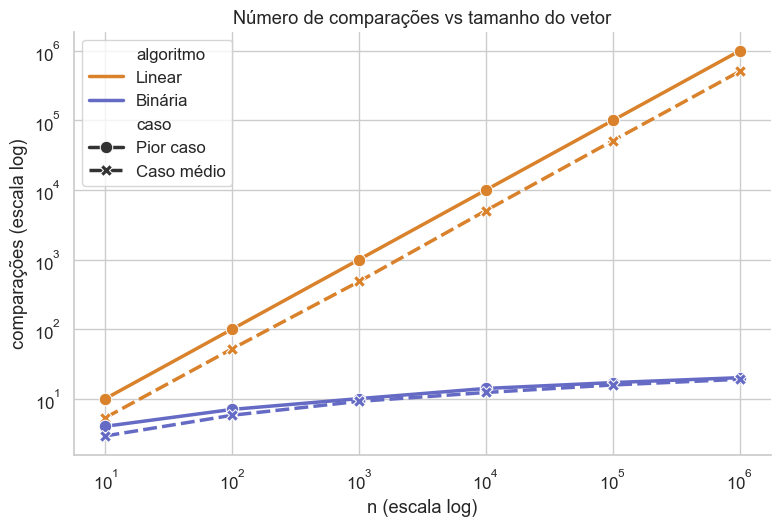

In [19]:
def grafico_comparacoes(dados: pd.DataFrame) -> Figure:
    """Comparações vs n, em escala log-log."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.lineplot(data=dados, x="n", y="comparacoes", hue="algoritmo", style="caso",
                 markers=True, palette=PALETA, linewidth=2.5, markersize=9, ax=ax)
    ax.set(xscale="log", yscale="log", xlabel="n (escala log)", ylabel="comparações (escala log)",
           title="Número de comparações vs tamanho do vetor")
    ax.legend(title=None, frameon=True)
    sns.despine(ax=ax)
    return fig


fig = grafico_comparacoes(df_comp); salvar_figura(fig, "1_comparacoes"); plt.show()

**Leitura:** a linear sobe em linha reta no gráfico log-log (cresce proporcional a *n*), enquanto a binária quase não sobe (cresce com *log n*).

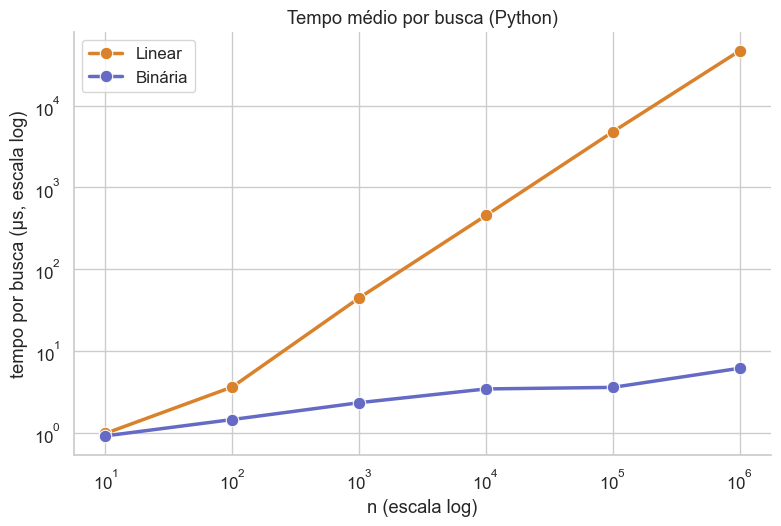

In [20]:
def grafico_tempo(dados: pd.DataFrame) -> Figure:
    """Tempo médio por busca vs n."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.lineplot(data=dados, x="n", y="tempo_us", hue="algoritmo", marker="o",
                 palette=PALETA, linewidth=2.5, markersize=9, ax=ax)
    ax.set(xscale="log", yscale="log", xlabel="n (escala log)", ylabel="tempo por busca (µs, escala log)",
           title="Tempo médio por busca (Python)")
    ax.legend(title=None, frameon=True)
    sns.despine(ax=ax)
    return fig


fig = grafico_tempo(df_tempo); salvar_figura(fig, "2_tempo"); plt.show()

**Leitura:** o tempo medido acompanha a teoria. Para *n* pequeno as duas ficam próximas (a binária tem mais passos por iteração); a diferença explode quando *n* cresce.

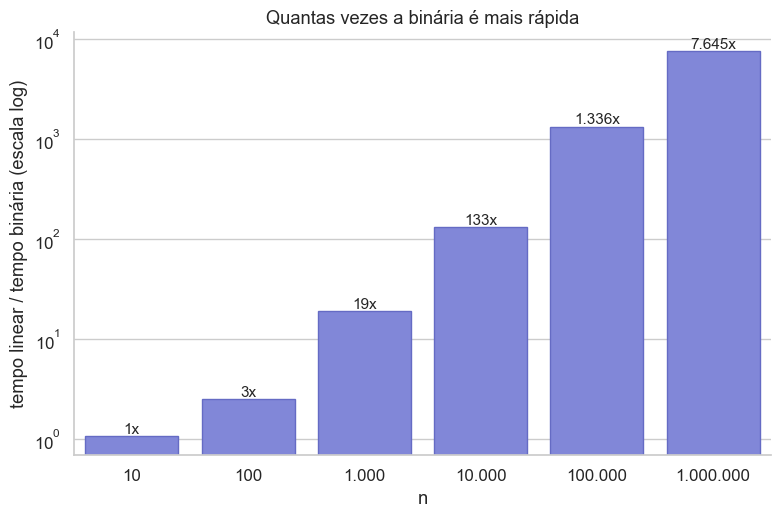

In [21]:
def grafico_speedup(dados: pd.DataFrame) -> Figure:
    """Quantas vezes a binária é mais rápida que a linear."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    dados = dados.assign(n_texto=dados["n"].map(lambda v: f"{v:,}".replace(",", ".")))
    sns.barplot(data=dados, x="n_texto", y="speedup", color=PRI, edgecolor=DEEP, ax=ax)
    ax.set_yscale("log")
    for barra, v in zip(ax.patches, dados["speedup"]):
        ax.annotate(f"{v:,.0f}x".replace(",", "."), (barra.get_x() + barra.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=11)
    ax.set(xlabel="n", ylabel="tempo linear / tempo binária (escala log)",
           title="Quantas vezes a binária é mais rápida")
    sns.despine(ax=ax)
    return fig


fig = grafico_speedup(df); salvar_figura(fig, "3_speedup"); plt.show()

C:\Users\Jp Lima\AppData\Local\Temp\ipykernel_5880\2215260026.py:4: UserWarning: Glyph 8970 (\N{LEFT FLOOR}) missing from font(s) Arial.
  fig.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
C:\Users\Jp Lima\AppData\Local\Temp\ipykernel_5880\2215260026.py:4: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
C:\Users\Jp Lima\AppData\Local\Temp\ipykernel_5880\2215260026.py:4: UserWarning: Glyph 8971 (\N{RIGHT FLOOR}) missing from font(s) Arial.
  fig.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
c:\Users\Jp Lima\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8970 (\N{LEFT FLOOR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Jp Lima\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_

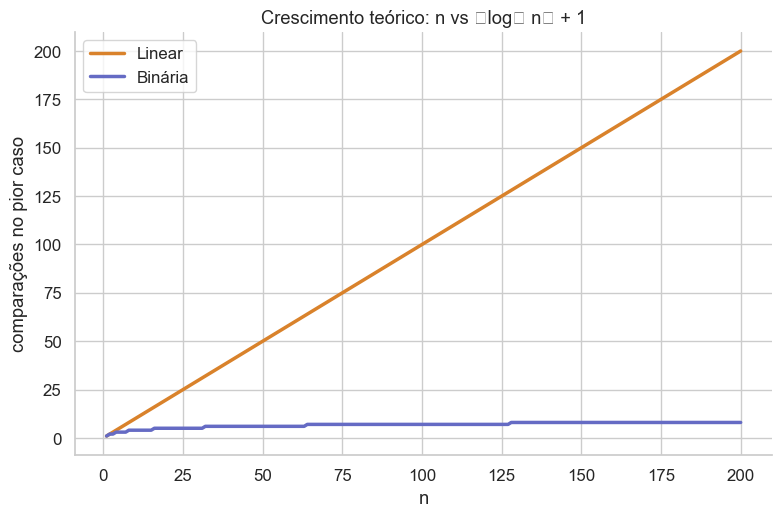

In [22]:
def grafico_teorico(dados: pd.DataFrame) -> Figure:
    """Crescimento teórico do pior caso para n pequeno (escala linear)."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.lineplot(data=dados, x="n", y="comparacoes", hue="algoritmo", palette=PALETA, linewidth=2.5, ax=ax)
    ax.set(xlabel="n", ylabel="comparações no pior caso",
           title="Crescimento teórico: n vs ⌊log₂ n⌋ + 1")
    ax.legend(title=None, frameon=True)
    sns.despine(ax=ax)
    return fig


fig = grafico_teorico(df_teorico); salvar_figura(fig, "4_teorico"); plt.show()

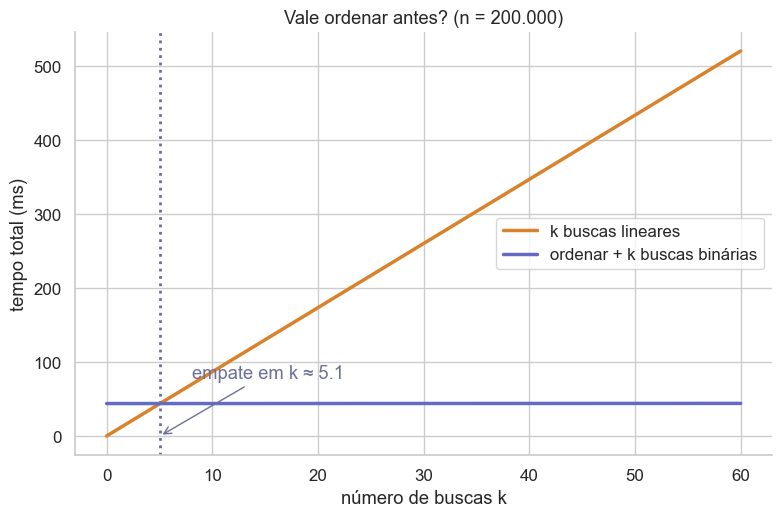

In [23]:
def grafico_equilibrio(dados: pd.DataFrame, k_eq: float, n: int = 200_000) -> Figure:
    """Ponto em que ordenar antes passa a compensar."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.lineplot(data=dados, x="k", y="tempo_ms", hue="estrategia",
                 palette=[AMBAR, DEEP], linewidth=2.5, ax=ax)
    ax.axvline(k_eq, color=CINZA, linestyle=":", linewidth=2)
    ax.annotate(f"empate em k ≈ {k_eq:.1f}", (k_eq, 0), xytext=(k_eq + 3, dados["tempo_ms"].max() * 0.15),
                color=CINZA, arrowprops=dict(arrowstyle="->", color=CINZA))
    ax.set(xlabel="número de buscas k", ylabel="tempo total (ms)",
           title=f"Vale ordenar antes? (n = {n:,})".replace(",", "."))
    ax.legend(title=None, frameon=True)
    sns.despine(ax=ax)
    return fig


fig = grafico_equilibrio(df_equilibrio, k_equilibrio); salvar_figura(fig, "5_ponto_equilibrio"); plt.show()

**Leitura:** ordenar custa Θ(n log n) uma vez; depois cada busca custa só Θ(log n). Passando de ~log₂ n buscas, ordenar primeiro já compensa.

## 7. Conclusões

| | Linear | Binária |
|---|---|---|
| Pré-requisito | nenhum | vetor **ordenado** |
| Pior caso | Θ(n) | Θ(log₂ n) |
| Espaço extra | O(1) | O(1) iterativa · O(log n) recursiva |
| Quando usar | poucas buscas ou dados sem ordem | muitas buscas em dados ordenados |

- O experimento confirma a teoria: o pior caso da binária coincide com ⌊log₂ n⌋ + 1.
- Os **tempos absolutos** variam de máquina para máquina; a **proporção** entre as buscas se mantém.
- A escolha depende do contexto: não existe algoritmo melhor em absoluto, existe o mais adequado ao uso.

### Boas práticas aplicadas neste notebook
- Uma responsabilidade por função, com *type hints* e *docstrings*.
- Constantes nomeadas e semente fixa para reprodutibilidade.
- Gerador `random.Random` local, sem alterar o estado global.
- Dados em formato longo (*tidy*) para o Seaborn; funções de gráfico devolvem `Figure`.
- Testes de corretude antes de qualquer medição de desempenho.